# 02. Качество сигнала

**Вопрос этапа:** меняется ли качество каналов от дня ко дню и насколько?

Основной расчёт — эксперимент `python run.py --config configs/quality_dev.yaml`
(код метрик в `src/quality.py`). Этот ноутбук **читает его результаты** и разбирает их, плюс содержит
проверки, которые не входят в эксперимент: шкала АЦП, артефактная попытка, два открытых вопроса.

Единица анализа — **канало-сессия**: один канал запястья у одного участника в одной сессии.
5 dev-участников × 3 сессии × 12 каналов = 180 строк.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from IPython.display import Image, display

from data import build_index, load_trial, FS, WRIST_IDX, GESTURE_SHORT, REST_GESTURE
import viz
viz.setup()
pd.set_option("display.width", 160)

res = json.loads((ROOT / "results" / "quality_dev.json").read_text(encoding="utf-8"))
q = pd.read_csv(ROOT / res["channel_table"])
idx = build_index()
idx = idx[idx.participant.isin(res["participants"])]
print(len(q), "channel-sessions;", "finished", res["finished"])

180 channel-sessions; finished 2026-10-19T19:44:25


## 1. Можно ли увидеть насыщение АЦП?

План просит «долю отсчётов у пределов шкалы АЦП». Для этого нужны **исходные коды АЦП**: 12 бит = 4096 ступенек.
Если сигнал упирается в предел, в записи появляются «плато» — несколько отсчётов подряд с одним и тем же крайним значением.

Проверяем, что лежит в файлах. `wfdb.rdrecord(..., physical=False)` отдаёт сырые целые числа, как они записаны в `.dat`.

In [2]:
rows = []
for (s, p, g, t) in [(1, 11, 11, 1), (1, 24, 17, 1), (2, 27, 15, 3)]:
    rec = wfdb.rdrecord(str(idx[(idx.session == s) & (idx.participant == p) & (idx.gesture == g) & (idx.trial == t)].path.iloc[0]),
                        physical=False)
    d = rec.d_signal[:, WRIST_IDX]
    for c in (0, 3):
        rows.append({"trial": f"s{s} p{p} g{g} t{t}", "channel": f"W{c + 1}",
                     "digital min": d[:, c].min(), "digital max": d[:, c].max(),
                     "unique values": len(np.unique(d[:, c])),
                     "gain, units/mV": round(rec.adc_gain[WRIST_IDX[c]])})
pd.DataFrame(rows)

,trial,channel,digital min,digital max,unique values,"gain, units/mV"
0,s1 p11 g11 t1,W1,-32767,32765,8383,72579
1,s1 p11 g11 t1,W4,-32767,32766,8254,28779
2,s1 p24 g17 t1,W1,-32767,32766,8067,1192898
3,s1 p24 g17 t1,W4,-32767,32765,8147,1179018
4,s2 p27 g15 t3,W1,-32767,32766,8102,255299
5,s2 p27 g15 t3,W4,-32767,32765,7900,125799


**Как читать:**
- Каждый канал каждого файла занимает **всю 16-битную шкалу** (−32767…32766), а коэффициент `gain` у всех разный.
  Значит, при сохранении каждый канал растянули под себя. «Предел шкалы» в файле — это просто максимум этого канала, а не предел АЦП.
- Уникальных значений ~8000 — больше, чем 4096 уровней 12-битного АЦП. Сетки исходных кодов не осталось:
  данные после записи пересчитывали (как минимум — режекторный фильтр 60 Гц, найденный на этапе 1).

Ищем плато на всех попытках и смотрим на максимальные амплитуды (это займёт около минуты).

In [3]:
max_abs, plateaus = [], 0
for r in idx.itertuples():
    rec = wfdb.rdrecord(r.path, physical=False)
    d = rec.d_signal[:, WRIST_IDX]
    x = (d - np.array(rec.baseline)[WRIST_IDX]) / np.array(rec.adc_gain)[WRIST_IDX]
    max_abs.append(np.abs(x).max())
    for c in range(12):
        for ext in (d[:, c].max(), d[:, c].min()):
            hit = np.concatenate([[0], (d[:, c] == ext).astype(int), [0]])
            runs = np.diff(np.flatnonzero(np.diff(hit)))[::2]   # lengths of runs at the extreme value
            plateaus += runs.max() >= 3
max_abs = np.array(max_abs)
print(f"plateaus (>= 3 equal extreme samples): {plateaus} of {len(idx) * 24}")
print(f"max |x| per trial, mV: median {np.median(max_abs):.2f}, 99% {np.percentile(max_abs, 99):.2f}, max {max_abs.max():.2f}")

plateaus (>= 3 equal extreme samples): 0 of 42840
max |x| per trial, mV: median 0.36, 99% 1.38, max 8.78


**Вывод:** плато нет нигде, но это не доказательство — фильтрация после записи сглаживает срезанные вершины.
Максимум 8,8 мВ больше моей оценки предела по паспорту (±5 мВ), так что и оценка предела не подтверждена.
**Насыщение напрямую не измерить**; косвенно ловим его по выбросам амплитуды (|x| > 5 мВ) — см. раздел 5.
Это ограничение датасета, его пишем в отчёт.

## 2. Метрики качества

Все метрики считаются по спектру Уэлча каждой попытки; мощность в полосе = сумма PSD по частотам полосы.

| Метрика | Что меряет | Чем плоха большая/малая величина |
|---|---|---|
| `noise_rms_uv` | RMS в 20–450 Гц **в покое** | высокий шум → плохой контакт или помехи |
| `signal_rms_uv` | RMS в 20–450 Гц **при жестах** | низкий → электрод над сухожилием, слабое усилие |
| `snr_db` | $20\log_{10}(\text{signal}/\text{noise})$ | итоговая «различимость» жеста на фоне покоя |
| `harm_frac_rest_pct` | доля мощности покоя в гармониках 120…420 Гц (±1 Гц) | **относительная**, см. раздел 4 |
| `harm_rms_rest_uv` | RMS этих гармоник, мкВ | абсолютная величина наводки |
| `low_frac_rest_pct` | доля мощности покоя ниже 20 Гц | движение электрода, дрейф контакта |
| `max_abs_mv`, `over_thr_pct` | максимум и доля отсчётов с \|x\| > 5 мВ | артефакты / возможное насыщение |
| `dead` | SD покоя < 0,5 мкВ | отклеенный электрод, обрыв |

Почему SNR через децибелы: отношения складываются как сумма, разброс симметричен.
+6 дБ ≈ в 2 раза по амплитуде, +20 дБ = в 10 раз.

In [4]:
cols = ["noise_rms_uv", "signal_rms_uv", "snr_db", "harm_frac_rest_pct", "harm_rms_rest_uv",
        "res60_frac_rest_pct", "low_frac_rest_pct", "max_abs_mv"]
q[cols].describe(percentiles=[0.05, 0.5, 0.95]).T[["min", "5%", "50%", "95%", "max"]].round(2)

,min,5%,50%,95%,max
noise_rms_uv,2.81,3.49,6.85,14.22,32.00
signal_rms_uv,17.54,23.61,43.02,83.96,109.37
snr_db,3.46,7.62,15.09,23.53,26.12
harm_frac_rest_pct,1.64,2.10,3.31,39.22,45.72
harm_rms_rest_uv,0.62,0.88,1.44,3.96,6.78
res60_frac_rest_pct,0.01,0.04,0.14,0.21,0.26
low_frac_rest_pct,0.63,2.80,5.99,17.54,30.00
max_abs_mv,0.25,0.32,0.71,8.59,8.78


**Как читать:** типичный канал запястья — шум покоя ~7 мкВ, сигнал жеста ~43 мкВ, SNR ~15 дБ (≈ в 6 раз по амплитуде).
Остаток 60 Гц ≤ 0,3 % — подтверждение, что 60 Гц вырезано ещё до нас. Мёртвых каналов нет (`dead` = 0).

Шум покоя (7 мкВ) выше паспортного шума усилителя (< 4 мкВ): в покое мы слышим в основном контакт кожа–электрод
и фоновый тонус мышц, а не электронику.

## 3. Карта SNR и дрейф между днями

Тепловая карта: каналы × участники, по панели на сессию, **одна цветовая шкала** на все три — иначе сравнивать сессии нельзя.

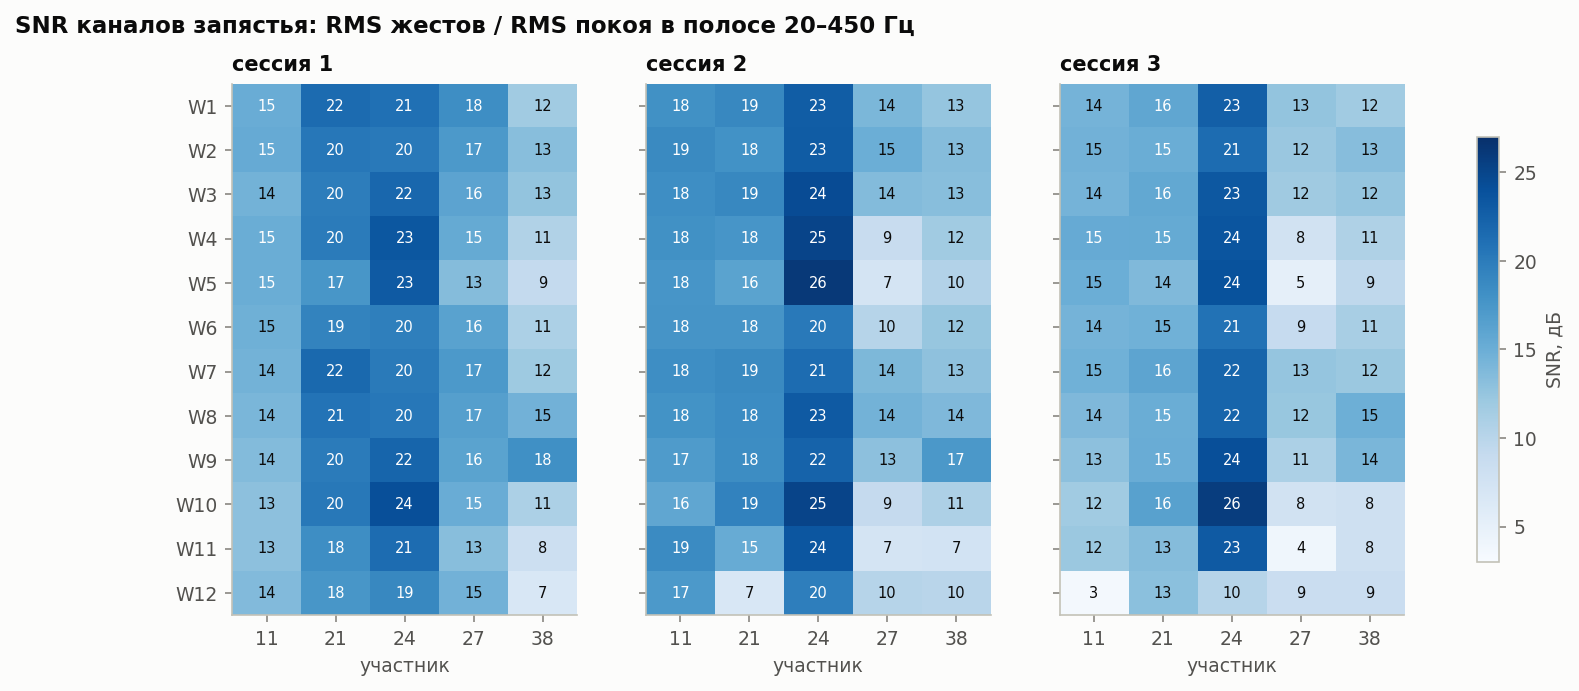

In [5]:
display(Image(ROOT / "reports" / "figures" / "02_snr_heatmap_quality_dev.png"))

**Как читать:**
- По горизонтали (между участниками) цвет меняется сильно: 24 тёмный (21–23 дБ), 38 светлый (~11 дБ). Люди очень разные.
- Между панелями (между днями) у одного участника меняется в основном **оттенок всего столбца**: у 27 столбец светлеет от сессии к сессии.
- Отдельные светлые клетки — отдельные плохие электроды: W12 у 11 в сессии 3, W12 у 21 в сессии 2.

Тот же SNR как линии — по панели на участника, цвет = сессия. Здесь лучше видно **форму** профиля по каналам.

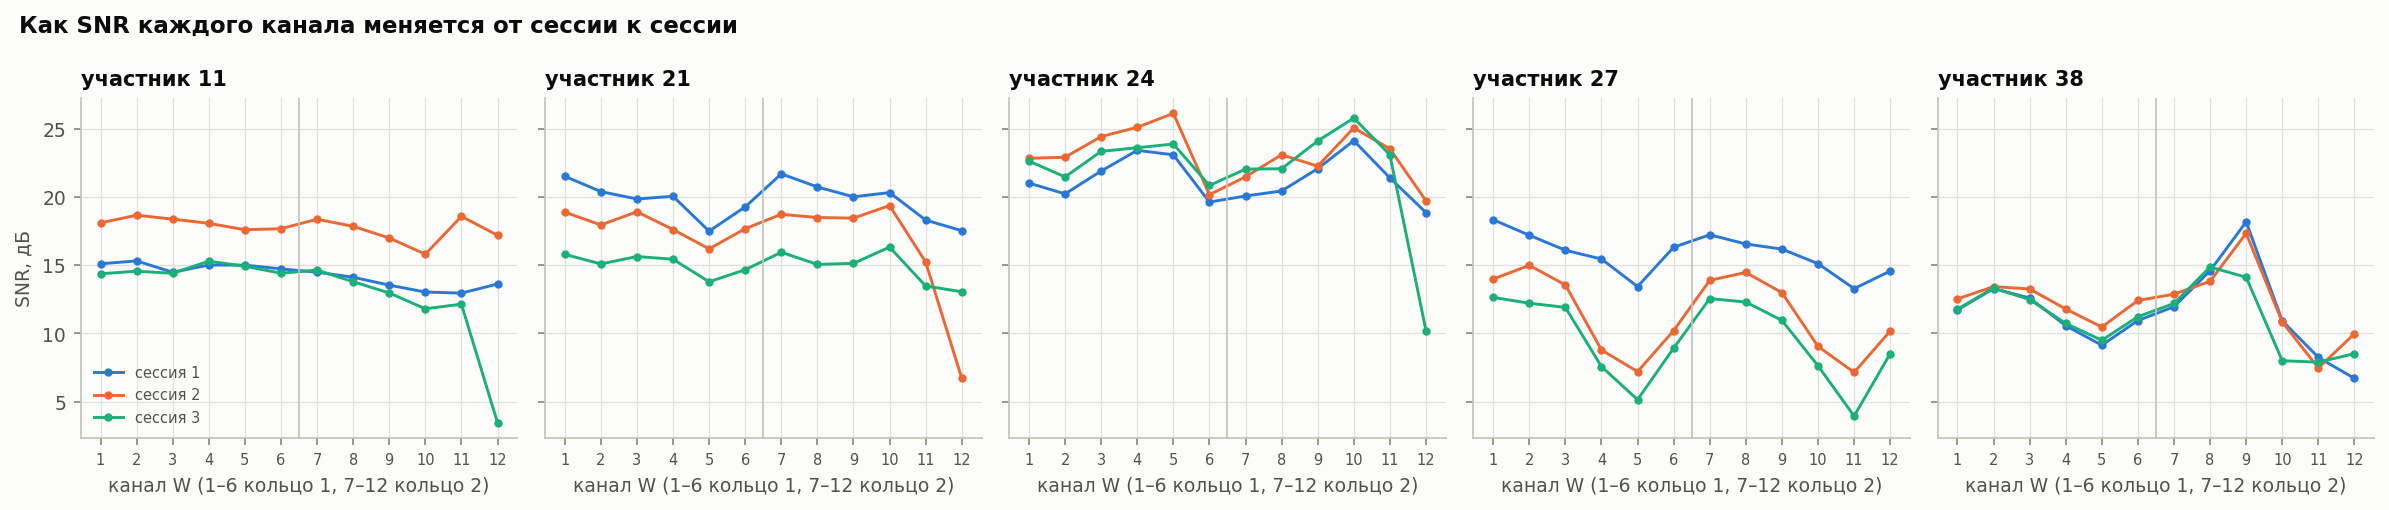

In [6]:
display(Image(ROOT / "reports" / "figures" / "02_snr_sessions_quality_dev.png"))

**Как читать:** если линии трёх сессий **параллельны**, но сдвинуты по высоте — это общий сдвиг (вся сессия лучше/хуже).
Если линия провалилась в одной точке — проблема одного электрода.

- Участник 38: линии почти совпадают — стабильное надевание.
- Участник 27: линии параллельны и опускаются — общий сдвиг.
- Участник 11: сессия 2 выше остальных на ~4 дБ целиком; в сессии 3 провал W12.
- Форма профиля у каждого человека своя и **повторяется изо дня в день** — это анатомия (где под браслетом мышцы, а где сухожилия).

Количественно: SNR канала = общий уровень сессии + отклонение канала. Сравниваем, насколько гуляет каждая часть.

In [7]:
def with_summary(d: pd.DataFrame) -> pd.DataFrame:
    """Append median / min / max over participants (the split itself is always within one participant)."""
    num = d.drop(columns=[d.columns[0], d.columns[1]])
    s = num.agg(["median", "min", "max"])
    s.insert(0, d.columns[0], ["медиана", "мин", "макс"])
    s.insert(1, d.columns[1], "")
    return pd.concat([d, s], ignore_index=True)

drift = pd.DataFrame(res["session_drift"]).round(2)
drift.columns = ["участник", "средний SNR сессий 1/2/3, дБ", "размах общего сдвига, дБ",
                 "медианный размах канала, дБ", "макс. размах канала, дБ", "SD поканального отклонения, дБ"]
with_summary(drift).round(2)

,участник,"средний SNR сессий 1/2/3, дБ","размах общего сдвига, дБ","медианный размах канала, дБ","макс. размах канала, дБ","SD поканального отклонения, дБ"
0,11,"[14.3, 17.8, 13.1]",4.71,3.98,13.73,1.36
1,21,"[19.8, 17.0, 14.9]",4.81,4.85,10.81,1.24
2,24,"[21.3, 23.1, 21.9]",1.71,2.08,9.52,1.37
3,27,"[15.8, 11.4, 9.5]",6.29,5.87,9.34,0.82
4,38,"[11.6, 12.2, 11.2]",0.96,1.13,4.06,0.75
5,медиана,,4.71,3.98,9.52,1.24
6,мин,,0.96,1.13,4.06,0.75
7,макс,,6.29,5.87,13.73,1.37


**Как считается:** $\text{SNR}_{s,c} = \mu_s + \alpha_c + \varepsilon_{s,c}$, отдельно **для каждого участника**:
$\mu_s$ — среднее по каналам сессии, $\alpha_c$ — постоянный профиль канала, $\varepsilon$ — остаток.
Номера сессий разных людей ничем не связаны, поэтому усреднять людей до разложения нельзя — дрейфы разных знаков
погасят друг друга. Нижние строки — медиана и диапазон **уже посчитанных** по участникам чисел.

**Вывод:** общий сдвиг SNR между днями — до 6,3 дБ (медиана 4,7), а отдельные каналы сверх него гуляют с SD ~1 дБ.
**Основной дрейф SNR — общий.** Редкие провалы отдельных электродов (до 14 дБ) — задача детектора плохих каналов.

Но SNR — отношение, и общий коэффициент усиления в нём сокращается. Значит, сдвиг SNR — **не** изменение масштаба,
а изменение соотношения сигнал/шум. Что сможет снять нормализация на этапе 5, видно только по **уровням** сигнала и шума —
раскладываем их так же.

In [8]:
import quality
cols_ru = ["участник", "средний уровень сессий 1/2/3, дБ", "размах общего сдвига, дБ",
           "медианный размах канала, дБ", "макс. размах канала, дБ", "SD поканального отклонения, дБ"]
q["signal_db"] = 20 * np.log10(q.signal_rms_uv)   # dB re 1 uV
q["noise_db"] = 20 * np.log10(q.noise_rms_uv)
for col, title in [("signal_db", "Уровень сигнала жестов"), ("noise_db", "Уровень шума покоя")]:
    d = quality.session_drift(q, col)
    d.columns = cols_ru
    print(title)
    display(with_summary(d).round(2))

Уровень сигнала жестов


,участник,"средний уровень сессий 1/2/3, дБ","размах общего сдвига, дБ","медианный размах канала, дБ","макс. размах канала, дБ","SD поканального отклонения, дБ"
0,11,"[34.9, 34.7, 34.2]",0.68,1.09,4.06,0.60
1,21,"[35.8, 32.6, 33.0]",3.18,3.19,4.35,0.24
2,24,"[36.5, 34.0, 34.9]",2.49,2.77,4.59,0.67
3,27,"[30.6, 29.2, 27.4]",3.20,3.28,6.55,0.86
4,38,"[31.7, 30.1, 30.5]",1.61,1.96,4.45,0.75
5,медиана,,2.49,2.77,4.45,0.67
6,мин,,0.68,1.09,4.06,0.24
7,макс,,3.20,3.28,6.55,0.86


Уровень шума покоя


,участник,"средний уровень сессий 1/2/3, дБ","размах общего сдвига, дБ","медианный размах канала, дБ","макс. размах канала, дБ","SD поканального отклонения, дБ"
0,11,"[20.6, 17.0, 21.1]",4.15,3.59,14.93,1.67
1,21,"[16.0, 15.6, 18.0]",2.43,3.40,7.54,1.31
2,24,"[15.1, 10.9, 13.0]",4.19,4.48,11.37,1.60
3,27,"[14.8, 17.9, 17.9]",3.09,3.00,7.57,1.07
4,38,"[20.2, 18.0, 19.3]",2.23,2.38,3.60,0.66
5,медиана,,3.09,3.40,7.57,1.31
6,мин,,2.23,2.38,3.60,0.66
7,макс,,4.19,4.48,14.93,1.67


**Как читать:** уровни в дБ относительно 1 мкВ, поэтому для средних по каналам SNR = сигнал − шум точно
(у 11: 34,9 − 20,6 = 14,3).

- **Сигнал жестов**: общий сдвиг 0,7–3,2 дБ, поканальный остаток всего 0,2–0,9 дБ. Амплитуда от дня ко дню меняется
  почти чистым **общим множителем** — именно это снимает нормализация по новой сессии на этапе 5.
- **Шум покоя**: общий сдвиг 2,2–4,2 дБ, поканальный остаток больше (0,7–1,7 дБ), а максимальный размах канала доходит
  до 15 дБ (W12 у 11). Проблемы отдельных электродов живут **в шуме**, то есть в контакте.
- Сдвиг SNR приходит с обеих сторон. У 11 и 24 — из шума (у 11 в сессии 2 сигнал 34,9 → 34,7, шум −3,6 дБ → SNR +3,5);
  у 21 в сессии 2 — из сигнала (−3,2 дБ при почти неизменном шуме); у 27 — из обоих.
  Такой сдвиг нормализацией не убрать: если отношение сигнал/шум упало, жесты действительно хуже различимы.

**Итого для этапа 5:** нормализация снимет общий масштаб амплитуды (~2–3 дБ), но не изменение SNR (до 6 дБ). Часть
потерь при переносе между днями останется и после нормализации.

### Профили каналов: повторяются ли они у человека и похожи ли у разных людей?

**Профиль сессии** — 12 чисел: SNR канала минус средний SNR по каналам этой сессии (общий сдвиг убран).
Профиль человека $\alpha_c$ — среднее его профилей по трём сессиям.

Сходство профилей меряем корреляцией Пирсона; **наблюдения — 12 каналов**:
- **внутри человека**: переменные — профиль сессии $a$ и профиль сессии $b$ одного участника (3 пары × 5 = 15 значений);
- **между людьми**: переменные — $\alpha_c$ участника A и $\alpha_c$ участника B (10 пар).

Сравнивать людей по номеру канала можно: по `Electrodelocation.pdf` кольца запястья ставятся по анатомическим ориентирам,
так что W1 у всех примерно в одном месте.

Априорная оценка (записана до расчёта): внутри человека 0,9, между людьми 0,7.

In [9]:
prof = quality.channel_profiles(q)                  # rows: (participant, session), columns: channels
alpha = prof.groupby(level="participant").mean()     # alpha_c of each participant
print("Профиль α_c (SNR канала минус среднее по каналам сессии, среднее по сессиям), дБ")
display(alpha.round(1))

rows = []
for label, sub in [("все 12 каналов", q), ("без W12", q[q.channel != "W12"])]:
    w, b = quality.profile_correlations(quality.channel_profiles(sub))
    for kind, r in [("внутри человека (15 пар сессий)", w.r), ("между людьми (10 пар)", b.r)]:
        rows.append({"каналы": label, "сравнение": kind, "медиана r": r.median(), "мин": r.min(), "макс": r.max()})
display(pd.DataFrame(rows).round(2))

w, _ = quality.profile_correlations(prof)
print("Внутри человека, по участникам (пары сессий 1-2, 1-3, 2-3):")
print(w.pivot(index="participant", columns="sessions", values="r").round(2))

lv = {col: quality.channel_profiles(q, col).groupby(level="participant").mean()["W12"]
      for col in ["signal_db", "noise_db"]}
print("\nW12 относительно среднего по каналам, дБ:")
print(pd.DataFrame(lv).round(1).T)

Профиль α_c (SNR канала минус среднее по каналам сессии, среднее по сессиям), дБ


channel,W1,W2,W3,W4,W5,W6,W7,W8,W9,W10,W11,W12
participant,,,,,,,,,,,,
11,0.8,1.1,0.7,1.1,0.8,0.6,0.8,0.2,-0.5,-1.5,-0.5,-3.6
21,1.5,0.6,0.9,0.5,-1.4,-0.0,1.5,0.8,0.6,1.4,-1.6,-4.8
24,0.0,-0.6,1.1,1.9,2.3,-1.9,-0.9,-0.2,0.7,2.9,0.6,-5.9
27,2.7,2.6,1.6,-1.6,-3.6,-0.4,2.3,2.2,1.1,-1.6,-4.1,-1.1
38,0.4,1.7,1.1,-0.6,-2.0,-0.1,0.7,2.8,4.9,-1.7,-3.8,-3.3


,каналы,сравнение,медиана r,мин,макс
0,все 12 каналов,внутри человека (15 пар сессий),0.85,0.39,0.98
1,все 12 каналов,между людьми (10 пар),0.54,-0.20,0.76
2,без W12,внутри человека (15 пар сессий),0.86,0.49,0.98
3,без W12,между людьми (10 пар),0.06,-0.54,0.78


Внутри человека, по участникам (пары сессий 1-2, 1-3, 2-3):
sessions      1-2   1-3   2-3
participant                  
11           0.52  0.55  0.39
21           0.72  0.88  0.81
24           0.88  0.73  0.71
27           0.88  0.92  0.98
38           0.93  0.85  0.87

W12 относительно среднего по каналам, дБ:
participant   11   21   24   27   38
signal_db   -1.9  0.3 -1.7 -0.3 -2.3
noise_db     1.7  5.1  4.2  0.9  1.0


**Как читать:**
- **Внутри человека** профиль повторяется: медиана r = 0,85 (без W12 — 0,86). Исключение — участник 11 (r ≈ 0,5): его профиль
  почти плоский (все каналы кроме W12 в пределах ±1,5 дБ), разброс между каналами мал, и корреляцию «съедает» шум оценки.
  Корреляция мала не только когда связи нет, но и когда у переменной мало собственного разброса.
- **Между людьми** с W12 медиана r = 0,54, без W12 — **0,06** (от −0,54 до 0,78). Почти всё сходство людей держится на одном канале:
  W12 хуже среднего у всех пятерых. Остальной профиль у каждого свой.
- Пирсон чувствителен к одной выбивающейся точке; Спирмен (по рангам) между людьми с W12 даёт медиану 0,22 — ещё одна подсказка,
  что 0,54 завышено одним каналом.
- W12 плох у всех за счёт **шума** (+0,9…+5,1 дБ к среднему по каналам), а не только сигнала. Это либо место установки
  (контакт там стабильно хуже), либо сам канал установки. Различить можно на всех 43 участниках.

**Вывод:** профиль канала — индивидуальное свойство человека, стабильное между днями (кроме общего для всех слабого W12).
Перенос между людьми должен быть труднее, чем между днями.

## 4. Открытый вопрос: почему SNR участника 27 падает?

SNR = сигнал / шум. Падение может прийти с любой стороны: шум вырос (контакт хуже) или сигнал упал (жесты слабее,
электроды легли на другое место). Раскладываем.

In [10]:
p27 = q[q.participant == 27].groupby("session")[["noise_rms_uv", "signal_rms_uv", "snr_db"]].median()
p27["noise vs s1, dB"] = 20 * np.log10(p27.noise_rms_uv / p27.noise_rms_uv.iloc[0])
p27["signal vs s1, dB"] = 20 * np.log10(p27.signal_rms_uv / p27.signal_rms_uv.iloc[0])
p27.round(2)

,noise_rms_uv,signal_rms_uv,snr_db,"noise vs s1, dB","signal vs s1, dB"
session,,,,,
1,5.27,32.54,16.13,0.00,0.00
2,8.83,28.48,11.59,4.48,-1.16
3,7.61,23.22,9.93,3.19,-2.93


**Как читать:** изменение SNR ≈ изменение сигнала − изменение шума (в дБ; для медиан равенство приближённое).
Рост шума указывает на контакт, падение сигнала — на силу жестов или положение электродов.

**Ответ для участника 27:** в сессии 2 падение почти целиком из-за шума (+4,5 дБ при −1,2 дБ сигнала) — хуже контакт.
В сессии 3 вклады сравнимы: шум всё ещё повышен (+3,2 дБ), и сигнал ослаб (−2,9 дБ) — жесты слабее или браслет сместился.

## 5. Ловушка относительной метрики: гармоники сети

Робастный поиск выбросов (|z| > 3 по медиане и MAD) пометил 26 канало-сессий участника 24 за высокую **долю** гармоник.
Но доля = гармоники / весь шум. Если весь шум очень мал, та же наводка займёт большую долю.

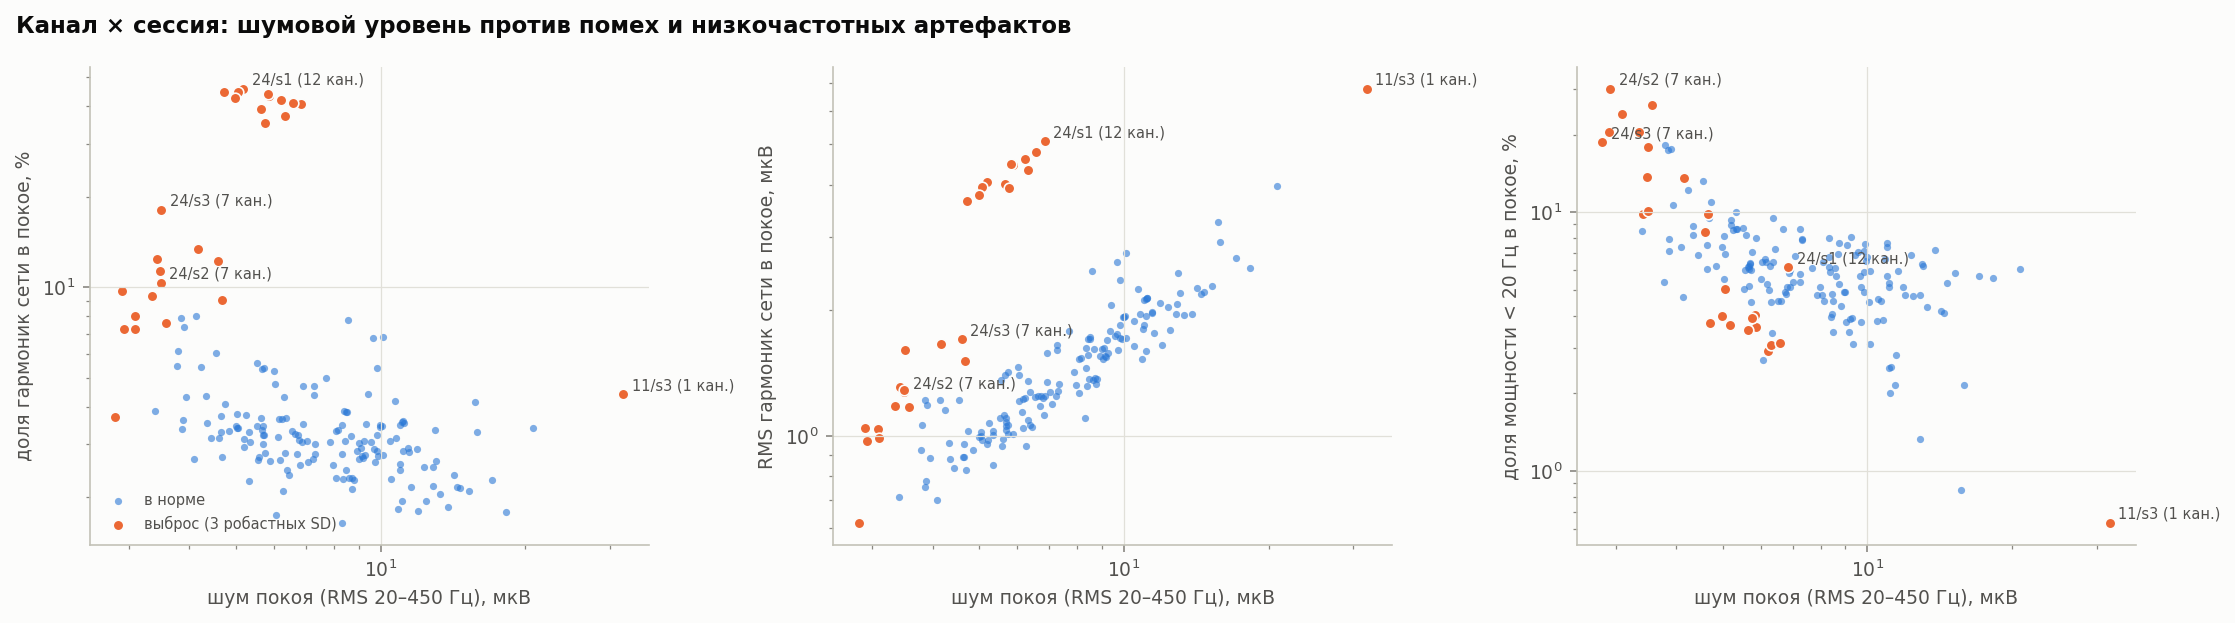

In [11]:
display(Image(ROOT / "reports" / "figures" / "02_outliers_quality_dev.png"))

Средняя панель: абсолютные гармоники растут вместе с шумом — общий тренд. Проверим, кто **отклоняется от тренда**:
подгоняем прямую $\log(\text{гармоники}) = a + b\log(\text{шум})$ робастно (по всем точкам кроме участника 24, чтобы он не тянул прямую)
и смотрим остаток в робастных SD.

In [12]:
lx, ly = np.log10(q.noise_rms_uv), np.log10(q.harm_rms_rest_uv)
fit = q.participant != 24
b, a = np.polyfit(lx[fit], ly[fit], 1)
resid = ly - (a + b * lx)
sd = 1.4826 * np.median(np.abs(resid[fit] - np.median(resid[fit])))
q["harm_trend_z"] = (resid - np.median(resid[fit])) / sd
q["harm_vs_trend"] = 10 ** (resid - np.median(resid[fit]))     # x times above the trend
print(f"slope b = {b:.2f}  (1.0 = harmonics proportional to noise); robust SD around the trend = x{10 ** sd:.2f}")
summary = q.groupby(["participant", "session"]).agg(
    harm_frac_pct=("harm_frac_rest_pct", "median"), harm_rms_uv=("harm_rms_rest_uv", "median"),
    noise_uv=("noise_rms_uv", "median"), vs_trend=("harm_vs_trend", "median"), trend_z=("harm_trend_z", "median"),
    flagged_old=("flag_reasons", lambda s: int(s.fillna("").str.contains("harm").sum())),
    flagged_trend=("harm_trend_z", lambda z: int((z > 3).sum())))
summary.round(2)

slope b = 0.87  (1.0 = harmonics proportional to noise); robust SD around the trend = x1.11


harm_frac_pct  harm_rms_uv  noise_uv  vs_trend  trend_z  flagged_old  flagged_trend
participant session                                                                                     
11          1                 2.76         1.84      9.86      0.99    -0.07            0              0
            2                 2.66         1.17      6.76      0.90    -1.01            0              0
            3                 4.30         2.32     10.05      1.25     2.16            0              5
21          1                 2.84         1.07      5.86      0.99    -0.12            0              0
            2                 3.32         0.97      4.95      0.99    -0.14            0              0
            3                 4.54         1.63      7.26      1.23     1.99            0              0
24          1                42.27         4.20      5.79      4.00    13.56           12             12
            2                 7.47         1.16      3.53      1.60     4.61            3             12
            3                 8.52         1.33      4.15      1.58     4.48            6              7
27          1                 3.30         1.00      5.27      1.03     0.28            0              0
            2                 3.25         1.44      8.83      1.02     0.21            0              0
            3                 3.04         1.36      7.61      0.98    -0.19            0              0
38          1                 2.72         1.75     10.27      0.95    -0.47            0              0
            2                 2.63         1.36      8.16      0.92    -0.80            0              0
            3                 3.20         1.71      9.19      1.03     0.33            0              0

**Как читать:** `vs_trend` — во сколько раз гармоники выше, чем ожидается при таком шуме; `flagged_old` — сколько каналов
пометила метрика «доля», `flagged_trend` — сколько каналов выше тренда больше чем на 3 робастных SD.

- У остальных участников точки лежат на тренде очень плотно (разброс ±11 %): наводка пропорциональна шуму.
- **Участник 24 выше тренда во всех трёх сессиях**: в 4 раза в сессии 1 и в ~1,6 раза в сессиях 2 и 3. Значит, у него
  повышенная наводка — свойство **человека** (кожа, тело, как он сидел относительно приборов), а в сессии 1 к этому добавилось
  что-то ещё (окружение, кабели). И везде сразу на всех 12 каналах — причина общая, не один электрод.
- При этом абсолютные величины малы: 1,2–4,2 мкВ против сигнала жеста ~70 мкВ. На SNR это не влияет (у 24 он лучший).

**Урок:** «доля» гармоник у 24/s2–s3 (7–8 %) и у 24/s1 (42 %) различается в 5 раз и сильно завышает картину; правильный вопрос —
выше ли помеха, чем ожидается при таком шуме. Относительную метрику всегда сверяйте с абсолютной величиной и с трендом.
Первая версия моего вывода («у 24/s2–s3 флаги ложные») оказалась неверной именно потому, что я судил по картинке, а не по остаткам.

## 6. Синфазный артефакт

Единственная отбракованная попытка (|x| > 5 мВ): участник 11, сессия 2.

trials with |x| > 5 mV: [('13 (FS)', 2)]


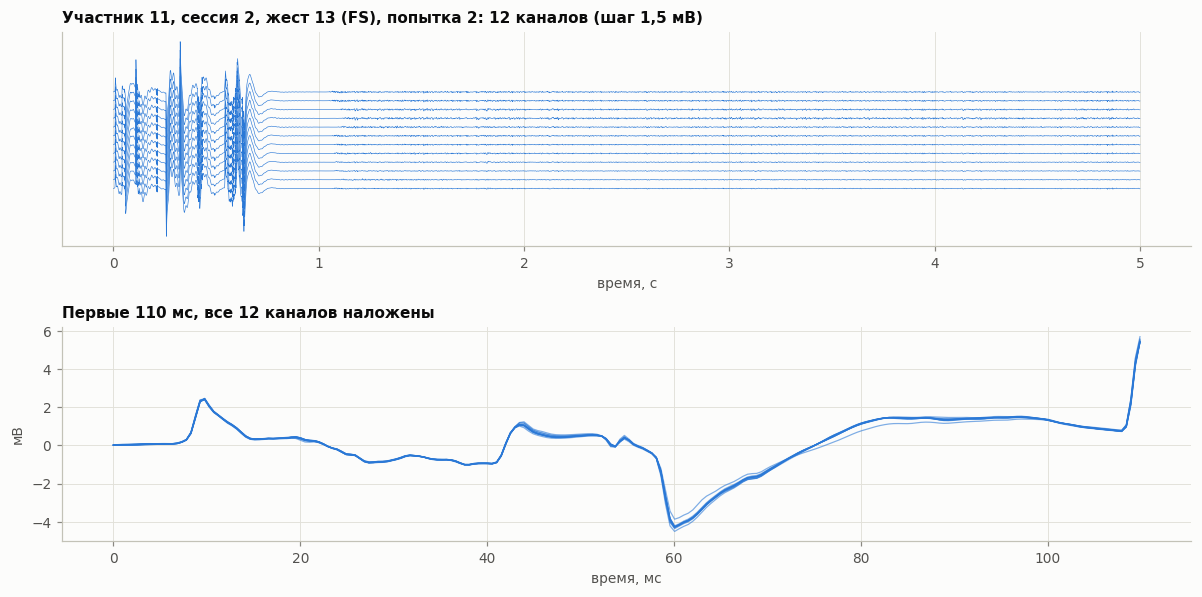

In [13]:
bad = []
for r in idx[(idx.participant == 11) & (idx.session == 2)].itertuples():
    x = load_trial(r.session, r.participant, r.gesture, r.trial)
    if np.abs(x - x.mean(0)).max() > 5:
        bad.append((r.gesture, r.trial))
print("trials with |x| > 5 mV:", [(f"{g} ({GESTURE_SHORT[g - 1]})", t) for g, t in bad])
G, T = bad[0]
X = load_trial(2, 11, G, T); X = X - X.mean(0)
t = np.arange(len(X)) / FS

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))
for c in range(12):
    axes[0].plot(t, X[:, c] - c * 1.5, lw=0.4, color=viz.SERIES[0])
    sel = t < 0.11
    axes[1].plot(t[sel] * 1000, X[sel, c], lw=0.8, color=viz.SERIES[0], alpha=0.6)
axes[0].set_title(f"Участник 11, сессия 2, жест {G} ({GESTURE_SHORT[G - 1]}), попытка {T}: 12 каналов (шаг 1,5 мВ)")
axes[0].set_xlabel("время, с"); axes[0].set_yticks([])
axes[1].set_title("Первые 110 мс, все 12 каналов наложены"); axes[1].set_xlabel("время, мс"); axes[1].set_ylabel("мВ")
fig.tight_layout()
viz.save(fig, "02_artifact_p11_s2");

**Как читать:** в первые ~0,7 с на **всех 12 каналах одна и та же** гладкая волна до 8,8 мВ — на нижней панели 12 линий
сливаются в одну. Потом тишина, и ЭМГ появляется только около 1,05 с.

Почему это не мышцы:
- ЭМГ — шумоподобный сигнал, разный на разных каналах; здесь форма гладкая и **одинаковая везде**;
- каждый канал — разность двух электродов, и одинаковое на всех каналах может прийти только через **общую цепь**:
  опорный электрод / землю или переходный процесс усилителя в начале записи.

Насколько это важно: одна такая попытка сдвигала мощность жестов всей сессии на 0,5–2 дБ. Поэтому в `quality.py`
попытки с |x| > 5 мВ исключаются из усреднения (и считаются в `n_rejected_trials`).

## Выводы

Все числа посчитаны внутри каждого участника; диапазоны — по 5 участникам.

1. **Качество меняется от дня ко дню**: средний SNR участника сдвигается между сессиями на 1,0–6,3 дБ (медиана 4,7).
2. **Основной дрейф — общий** (все каналы сессии вместе), поканальный остаток ~1 дБ. Но у него две части:
   общий масштаб амплитуды (сигнал, 0,7–3,2 дБ) — его снимет нормализация по новой сессии на этапе 5;
   и изменение SNR (через шум покоя — контакт, или через сигнал — сила жестов, положение) — его нормализация не снимет.
3. **Профиль SNR по каналам у человека стабилен, у разных людей разный**: корреляция профилей между сессиями одного человека — медиана 0,85,
   между людьми без W12 — 0,06. Общее у всех только одно: шумный W12. → Перенос между людьми, вероятно, труднее, чем между днями (этап 3, E2 vs E3).
4. **Плохой электрод в отдельной сессии** — второй, более редкий тип дрейфа (до 14 дБ), и проявляется он в шуме. Высокий шум при нормальном сигнале = контакт; слабый сигнал при нормальном шуме = электрод над сухожилием.
5. **Относительные метрики обманывают на чистых каналах** — сверять с абсолютными и с трендом. Повышенная наводка у участника 24 во всех сессиях (×1,6, в сессии 1 ×4), но в абсолютных величинах мала и на SNR не влияет.
6. **Насыщение АЦП в этом датасете напрямую не измерить** — ограничение для отчёта.